1990 -> 559 kayit
1991 -> 928 kayit
1992 -> 583 kayit
1993 -> 2328 kayit
1994 -> 2628 kayit
1995 -> 879 kayit
1996 -> 557 kayit
1997 -> 315 kayit
1998 -> 1114 kayit
1999 -> 1344 kayit
2000 -> 311 kayit
2001 -> 466 kayit
2002 -> 216 kayit
2003 -> 315 kayit
2004 -> 971 kayit
2005 -> 1207 kayit
2006 -> 704 kayit
2007 -> 713 kayit
2008 -> 569 kayit
2009 -> 38 kayit
2010 -> 53 kayit
2011 -> 246 kayit
2012 -> 123 kayit
2013 -> 78 kayit
2014 -> 90 kayit
2015 -> 73 kayit
2016 -> 53 kayit
2017 -> 133 kayit
2018 -> 70 kayit
2019 -> 93 kayit
2020 -> 192 kayit
2021 -> 160 kayit
2022 -> 97 kayit
2023 -> 677 kayit
2024 -> 126 kayit
2025 -> 294 kayit
2026 -> 74 kayit
Toplam ham kayit: 19377
Temiz kayit: 19375
magType
md     9685
ml     5266
mb     3633
mwr     331
mww     177
mwc     126
m       112
mwb      21
Name: count, dtype: int64
6 Subat - 6 Mart 2023 kayit: 478
                         time  mag  \
18216 2023-02-06 01:17:34.342  7.8   
18316 2023-02-06 10:24:48.811  7.5   
18218 2023-02-06 01

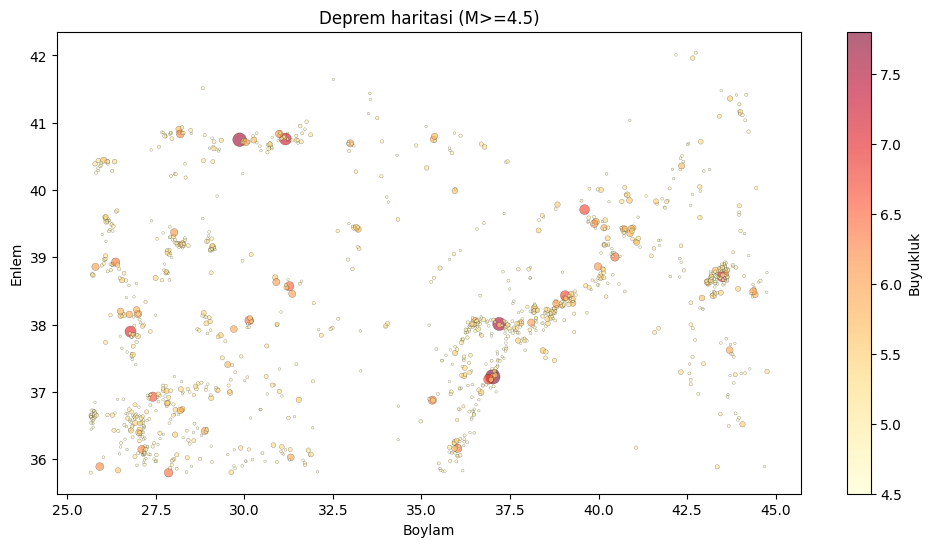

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
import io, time, requests
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://earthquake.usgs.gov/fdsnws/event/1/query"
PARAMS = {
    "format": "csv",
    "minlatitude": 35.8, "maxlatitude": 42.1,
    "minlongitude": 25.66, "maxlongitude": 44.8,
    "minmagnitude": 2.5, "orderby": "time-asc", "limit": 20000,
}

# --- 1) Veriyi yil yil cek ---
parcalar = []
for yil in range(1990, 2027):
    p = dict(PARAMS)
    p["starttime"] = f"{yil}-01-01"
    p["endtime"] = f"{yil+1}-01-01"
    try:
        r = requests.get(URL, params=p, timeout=60)
        r.raise_for_status()
        d = pd.read_csv(io.StringIO(r.text))
        parcalar.append(d)
        print(yil, "->", len(d), "kayit")
        if len(d) >= 20000:
            print("   UYARI: 20.000 siniri doldu, veri eksik olabilir!")
    except Exception as e:
        print(yil, "HATA:", e)
    time.sleep(0.5)

ham = pd.concat(parcalar, ignore_index=True)
print("Toplam ham kayit:", len(ham))

# --- 2) Temizle ---
df = ham[ham["type"] == "earthquake"]
df = df[["id", "time", "latitude", "longitude", "depth", "mag", "magType", "place"]]
df["time"] = pd.to_datetime(df["time"], utc=True).dt.tz_localize(None)
df["yil"] = df["time"].dt.year
df = df.dropna(subset=["latitude", "longitude", "depth", "mag"])
df = df.drop_duplicates(subset="id")
df = df[(df["mag"] >= 2.5) & (df["mag"] <= 10)]
df["depth"] = df["depth"].clip(lower=0)
df["magType"] = df["magType"].str.lower()
df = df.sort_values("time").reset_index(drop=True)
print("Temiz kayit:", len(df))
print(df["magType"].value_counts().head(8))

# --- 3) 6 Subat 2023 ---
subat = df[(df["time"] >= "2023-02-06") & (df["time"] < "2023-03-07")]
print("6 Subat - 6 Mart 2023 kayit:", len(subat))
print(subat.sort_values("mag", ascending=False).head(5)[["time", "mag", "place"]])

# --- 4) Harita ---
b = df[df["mag"] >= 4.5]
plt.figure(figsize=(12, 6))
sc = plt.scatter(b["longitude"], b["latitude"], c=b["mag"],
                 s=(b["mag"] - 3) ** 3, cmap="YlOrRd", alpha=0.6,
                 edgecolor="k", linewidth=0.2)
plt.colorbar(sc, label="Buyukluk")
plt.title("Deprem haritasi (M>=4.5)")
plt.xlabel("Boylam"); plt.ylabel("Enlem")
plt.show()

# --- 5) Kaydet ve indir ---
df.to_csv("deprem_temiz.csv", index=False)
from google.colab import files
files.download("deprem_temiz.csv")


Kullanilan deprem sayisi: 4217
Bulunan bolge sayisi: 32
Hicbir bolgeye girmeyen (gurultu): 1458
       sayi  maks_mag      enlem     boylam
bolge                                      
12      641       7.8  37.952953  37.615232
0       457       6.6  36.461833  27.253817
18      234       7.1  38.725891  43.392355
16      160       5.0  36.592316  25.732112
6       124       6.1  39.196794  28.028709
15      122       7.0  37.984625  26.845439
3       109       5.5  37.037226  28.894557
19      105       7.2  40.747030  31.035886
7        89       6.3  38.824039  26.246739
8        75       6.3  36.165835  36.022485


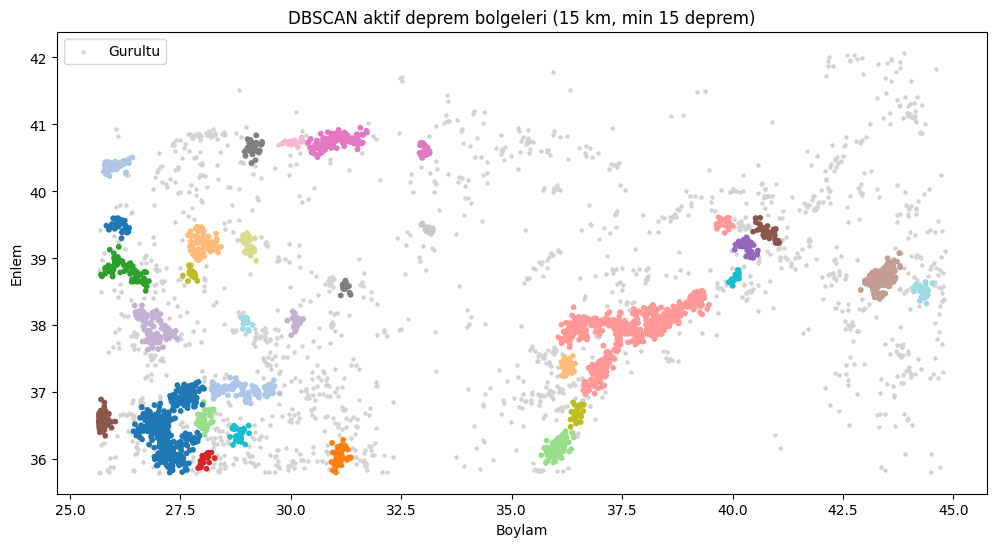

In [3]:
import numpy as np
from sklearn.cluster import DBSCAN

# M>=4.0 depremleri kullan (kucuk depremler gurultu yapar)
d = df[df["mag"] >= 4.0].copy()
print("Kullanilan deprem sayisi:", len(d))

# DBSCAN icin koordinatlar radyan olmali
koordinat = np.radians(d[["latitude", "longitude"]].values)

KM = 15         # komsuluk yaricapi (km)
eps = KM / 6371  # radyana cevir (dunya yaricapi 6371 km)

db = DBSCAN(eps=eps, min_samples=15, metric="haversine", algorithm="ball_tree")
d["bolge"] = db.fit_predict(koordinat)

print("Bulunan bolge sayisi:", d["bolge"].max() + 1)
print("Hicbir bolgeye girmeyen (gurultu):", (d["bolge"] == -1).sum())

# Bolge ozeti
ozet = (d[d["bolge"] >= 0].groupby("bolge")
        .agg(sayi=("mag", "size"), maks_mag=("mag", "max"),
             enlem=("latitude", "mean"), boylam=("longitude", "mean"))
        .sort_values("sayi", ascending=False))
print(ozet.head(10))

# Harita
plt.figure(figsize=(12, 6))
g = d[d["bolge"] == -1]
plt.scatter(g["longitude"], g["latitude"], c="lightgray", s=5, label="Gurultu")
b = d[d["bolge"] >= 0]
plt.scatter(b["longitude"], b["latitude"], c=b["bolge"], cmap="tab20", s=10)
plt.title(f"DBSCAN aktif deprem bolgeleri ({KM} km, min 15 deprem)")
plt.xlabel("Boylam"); plt.ylabel("Enlem")
plt.legend()
plt.show()

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import numpy as np
import geopandas as gpd

ESIK = 4.0   # sadece M>=4.0 depremleri say (tamamlilik sorunu icin)

# --- 1) Il sinirlarini indir ---
URL = "https://raw.githubusercontent.com/cihadturhan/tr-geojson/master/geo/tr-cities-utf8.json"
iller = gpd.read_file(URL)
if iller.crs is None:
    iller = iller.set_crs(4326)
else:
    iller = iller.to_crs(4326)

adaylar = [c for c in iller.columns if c != "geometry" and iller[c].dtype == "object"]
il_sutunu = adaylar[0]
tum_iller = sorted(iller[il_sutunu].unique())
print("Il adi sutunu:", il_sutunu, "| Il sayisi:", len(tum_iller))

# --- 2) Depremleri illere bagla ---
d = df[df["mag"] >= ESIK].copy()
noktalar = gpd.GeoDataFrame(
    d, geometry=gpd.points_from_xy(d["longitude"], d["latitude"]), crs=4326
)
bagli = gpd.sjoin(noktalar, iller[[il_sutunu, "geometry"]], predicate="within", how="inner")
bagli = bagli.rename(columns={il_sutunu: "il"})
print(f"\nM>={ESIK} deprem sayisi:", len(d))
print("Bir ilin icine dusen:", len(bagli))
print("Il disinda kalan (deniz, komsu ulke):", len(d) - len(bagli))

# --- 3) Il bazli ozellikler ---
ozet = bagli.groupby("il").agg(
    deprem_sayisi=("mag", "size"),
    maks_mag=("mag", "max"),
    m5_sayisi=("mag", lambda x: (x >= 5).sum()),
    ort_derinlik=("depth", "mean"),
)

# 6 Subat 2023 artcilari haric sayi
artci = (bagli["time"] >= "2023-02-06") & (bagli["time"] < "2023-03-07")
ozet["deprem_sayisi_artcisiz"] = bagli[~artci].groupby("il").size()

# Son 10 yil egilimi (2016-2025)
son10 = bagli[(bagli["yil"] >= 2016) & (bagli["yil"] <= 2025)]
yillik = son10.groupby(["il", "yil"]).size().unstack(fill_value=0)
yillik = yillik.reindex(columns=range(2016, 2026), fill_value=0)
egilim = yillik.apply(lambda s: np.polyfit(range(10), s.values, 1)[0], axis=1)
ozet["son10_egilim"] = egilim
ozet["son10_toplam"] = yillik.sum(axis=1)

# Hic depremi olmayan illeri de tabloya ekle (81 il olsun)
eksik = [i for i in tum_iller if i not in ozet.index]
print("\nHic M>=4 depremi olmayan iller:", eksik)
ozet = ozet.reindex(tum_iller)

# Bos kalanlari doldur: sayilar 0, derinlik ortalama
for c in ["deprem_sayisi", "maks_mag", "m5_sayisi", "deprem_sayisi_artcisiz",
          "son10_egilim", "son10_toplam"]:
    ozet[c] = ozet[c].fillna(0)
ozet["ort_derinlik"] = ozet["ort_derinlik"].fillna(ozet["ort_derinlik"].mean())
ozet = ozet.round(2).sort_values("deprem_sayisi", ascending=False)

print("\nTablodaki il sayisi:", len(ozet))
print("Bos (NaN) deger sayisi:", int(ozet.isna().sum().sum()))
print("\nEn cok deprem olan 15 il:")
print(ozet.head(15))

ozet.to_csv("il_ozellikleri.csv", encoding="utf-8-sig")
from google.colab import files
files.download("il_ozellikleri.csv")

Il adi sutunu: name | Il sayisi: 81

M>=4.0 deprem sayisi: 4217
Bir ilin icine dusen: 2744
Il disinda kalan (deniz, komsu ulke): 1473

Hic M>=4 depremi olmayan iller: ['Artvin', 'Batman', 'Edirne', 'Giresun', 'Karabük', 'Kırklareli', 'Mardin', 'Nevşehir', 'Sinop', 'Trabzon', 'Uşak', 'Zonguldak', 'İstanbul']

Tablodaki il sayisi: 81
Bos (NaN) deger sayisi: 0

En cok deprem olan 15 il:
               deprem_sayisi  maks_mag  m5_sayisi  ort_derinlik  \
il                                                                
Kahramanmaraş          292.0       7.8       19.0          9.83   
Van                    280.0       7.1       18.0          8.47   
Malatya                152.0       6.0       19.0          9.61   
Muğla                  131.0       5.8       12.0         14.69   
Adıyaman               114.0       5.6       11.0         11.65   
Balıkesir              106.0       6.1        5.0         10.98   
Bingöl                  96.0       6.4       13.0          9.93   
Adana     

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import unicodedata

NUFUS_2021 = {
"Adana":2263373,"Adıyaman":632148,"Afyonkarahisar":744179,"Ağrı":524069,"Amasya":335331,
"Ankara":5747325,"Antalya":2619832,"Artvin":169543,"Aydın":1134031,"Balıkesir":1250610,
"Bilecik":228334,"Bingöl":283112,"Bitlis":352277,"Bolu":320014,"Burdur":273716,
"Bursa":3147818,"Çanakkale":557276,"Çankırı":196515,"Çorum":526282,"Denizli":1051056,
"Diyarbakır":1791373,"Edirne":412115,"Elazığ":588088,"Erzincan":237351,"Erzurum":756893,
"Eskişehir":898369,"Gaziantep":2130432,"Giresun":450154,"Gümüşhane":150119,"Hakkâri":278218,
"Hatay":1670712,"Isparta":445678,"Mersin":1891145,"İstanbul":15840900,"İzmir":4425789,
"Kars":281077,"Kastamonu":375592,"Kayseri":1434357,"Kırklareli":366363,"Kırşehir":242944,
"Kocaeli":2033441,"Konya":2277017,"Kütahya":578640,"Malatya":808692,"Manisa":1456626,
"Kahramanmaraş":1171298,"Mardin":862757,"Muğla":1021141,"Muş":405228,"Nevşehir":308003,
"Niğde":363725,"Ordu":760872,"Rize":345662,"Sakarya":1060876,"Samsun":1371274,
"Siirt":331980,"Sinop":218408,"Sivas":636121,"Tekirdağ":1113400,"Tokat":602567,
"Trabzon":816684,"Tunceli":83645,"Şanlıurfa":2143020,"Uşak":373183,"Van":1141015,
"Yozgat":418500,"Zonguldak":589684,"Aksaray":429069,"Bayburt":85042,"Karaman":258838,
"Kırıkkale":275968,"Batman":626319,"Şırnak":546589,"Bartın":201711,"Ardahan":94932,
"Iğdır":203159,"Yalova":291001,"Karabük":249287,"Kilis":145826,"Osmaniye":553012,"Düzce":400976,
}

def sade(s):
    s = str(s).replace("İ", "I").replace("ı", "i")
    s = unicodedata.normalize("NFKD", s)
    s = "".join(c for c in s if not unicodedata.combining(c))
    return s.lower().strip()

nufus_sade = {sade(k): v for k, v in NUFUS_2021.items()}
takma_ad = {"afyon": "afyonkarahisar", "icel": "mersin"}

def nufus_bul(il):
    k = sade(il)
    k = takma_ad.get(k, k)
    return nufus_sade.get(k)

tablo = ozet.copy()
tablo["nufus"] = [nufus_bul(i) for i in tablo.index]

eslesmeyen = tablo[tablo["nufus"].isna()].index.tolist()
print("Nufusu eslesmeyen iller:", eslesmeyen)
print("Eslesen il sayisi:", int(tablo["nufus"].notna().sum()), "/", len(tablo))

# 100 bin kisi basina M>=4 deprem sayisi
tablo["deprem_100bin"] = (tablo["deprem_sayisi_artcisiz"] / tablo["nufus"] * 100000).round(2)

print(tablo[["deprem_sayisi", "maks_mag", "nufus", "deprem_100bin"]].head(12))

tablo.to_csv("il_ozellikleri_nufus.csv", encoding="utf-8-sig")
from google.colab import files
files.download("il_ozellikleri_nufus.csv")

Nufusu eslesmeyen iller: []
Eslesen il sayisi: 81 / 81
               deprem_sayisi  maks_mag    nufus  deprem_100bin
il                                                            
Kahramanmaraş          292.0       7.8  1171298           8.54
Van                    280.0       7.1  1141015          24.54
Malatya                152.0       6.0   808692          10.63
Muğla                  131.0       5.8  1021141          12.83
Adıyaman               114.0       5.6   632148           7.12
Balıkesir              106.0       6.1  1250610           8.48
Bingöl                  96.0       6.4   283112          31.44
Adana                   91.0       6.3  2263373           3.76
Hatay                   89.0       6.3  1670712           1.62
Elazığ                  80.0       6.7   588088          12.07
Manisa                  79.0       5.6  1456626           5.42
Denizli                 68.0       5.7  1051056           6.47


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Il sayisi: 81 | Bos deger: 0

k ve silhouette skoru (yuksek = daha iyi ayrisma):
  k=3: 0.409
  k=4: 0.442
  k=5: 0.461
  k=6: 0.419
  k=7: 0.440

Risk skoruna gore iller:

Risk 5 (5 il): Kahramanmaraş, Malatya, Balıkesir, Adıyaman, Hatay

Risk 4 (28 il): Van, Elazığ, Bingöl, Muğla, Denizli, Kütahya, Düzce, Adana, Manisa, Erzincan, İzmir, Erzurum, Afyon, Ankara, Osmaniye, Sakarya, Gaziantep, Kocaeli, Tunceli, Bolu, Konya, Çanakkale, Tokat, Amasya, Diyarbakır, Hakkari, Kars, Burdur

Risk 3 (34 il): Muş, Kayseri, Çorum, Sivas, Isparta, Yozgat, Siirt, Çankırı, Yalova, Iğdır, Bitlis, Aydın, Şırnak, Kırşehir, Aksaray, Kastamonu, Bursa, Ağrı, Bartın, Niğde, Ardahan, Karaman, Bayburt, Şanlıurfa, Kilis, Kırıkkale, Bilecik, Gümüşhane, Rize, Samsun, Ordu, Mersin, Tekirdağ, Eskişehir

Risk 2 (13 il): Artvin, Batman, Karabük, Edirne, Giresun, Kırklareli, Sinop, Mardin, Nevşehir, Uşak, Trabzon, Zonguldak, İstanbul

Risk 1 (1 il): Antalya

Skor basina ortalama:
            deprem_sayisi_artcisiz  ma

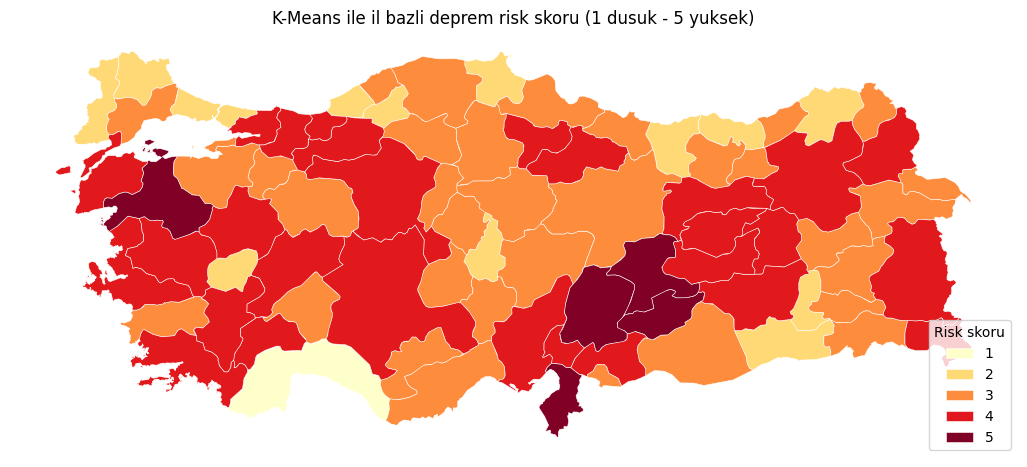

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# --- 1) Veriyi GitHub'dan oku ---
CSV = "https://raw.githubusercontent.com/nisanurguzel/deprem-sigorta-riskanalizi/main/01_Veri/il_ozellikleri_nufus.csv"
t = pd.read_csv(CSV, index_col=0)
t.index.name = "il"
print("Il sayisi:", len(t), "| Bos deger:", int(t.isna().sum().sum()))

# --- 2) Ozellikleri hazirla ---
X = pd.DataFrame(index=t.index)
X["log_deprem"] = np.log1p(t["deprem_sayisi_artcisiz"])   # artcisiz sayi
X["maks_mag"] = t["maks_mag"]
X["log_m5"] = np.log1p(t["m5_sayisi"])
X["ort_derinlik"] = t["ort_derinlik"]
X["son10_egilim"] = t["son10_egilim"]

KULLAN_NUFUS = False   # True yapip sonucu karsilastirabilirsin
if KULLAN_NUFUS:
    X["log_nufus"] = np.log(t["nufus"])

Z = StandardScaler().fit_transform(X)

# --- 3) Kac grup (k) secelim? Silhouette'e bak ---
print("\nk ve silhouette skoru (yuksek = daha iyi ayrisma):")
for k in range(3, 8):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Z)
    print(f"  k={k}: {silhouette_score(Z, km.labels_):.3f}")

# --- 4) K=5 ile grupla ---
K = 5
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(Z)
t["kume"] = km.labels_

# --- 5) Gruplari tehlikeye gore sirala -> 1-5 risk skoru ---
Zdf = pd.DataFrame(Z, index=X.index, columns=X.columns)
tehlike = (Zdf["log_deprem"] + Zdf["maks_mag"] + Zdf["log_m5"] - Zdf["ort_derinlik"]) / 4
t["tehlike_puani"] = tehlike.round(2)   # sig derinlik = daha tehlikeli
sira = t.groupby("kume")["tehlike_puani"].mean().rank().astype(int)   # 1..5
t["risk_skoru"] = t["kume"].map(sira)

print("\nRisk skoruna gore iller:")
for s in range(5, 0, -1):
    liste = t[t["risk_skoru"] == s].sort_values("tehlike_puani", ascending=False).index.tolist()
    print(f"\nRisk {s} ({len(liste)} il): {', '.join(liste)}")

print("\nSkor basina ortalama:")
print(t.groupby("risk_skoru")[["deprem_sayisi_artcisiz", "maks_mag", "m5_sayisi", "ort_derinlik"]].mean().round(2))

# --- 6) Harita ---
URL = "https://raw.githubusercontent.com/cihadturhan/tr-geojson/master/geo/tr-cities-utf8.json"
iller = gpd.read_file(URL)
il_sutunu = [c for c in iller.columns if c != "geometry" and iller[c].dtype == "object"][0]
harita = iller.merge(t[["risk_skoru"]], left_on=il_sutunu, right_index=True, how="left")
print("\nHaritada eslesmeyen il:", int(harita["risk_skoru"].isna().sum()))

fig, ax = plt.subplots(figsize=(13, 6))
harita.plot(column="risk_skoru", cmap="YlOrRd", categorical=True, legend=True,
            edgecolor="white", linewidth=0.4, ax=ax,
            legend_kwds={"title": "Risk skoru", "loc": "lower right"})
ax.set_title("K-Means ile il bazli deprem risk skoru (1 dusuk - 5 yuksek)")
ax.set_axis_off()
plt.savefig("risk_haritasi.png", dpi=150, bbox_inches="tight")
plt.show()

# --- 7) Kaydet ---
t.to_csv("il_risk_skorlari.csv", encoding="utf-8-sig")
from google.colab import files
files.download("il_risk_skorlari.csv")
files.download("risk_haritasi.png")

In [8]:
import pandas as pd

CSV = "https://raw.githubusercontent.com/nisanurguzel/deprem-sigorta-riskanalizi/main/01_Veri/il_risk_skorlari.csv"
t = pd.read_csv(CSV, index_col=0)

# --- 1) Risk skorundan prim katsayisi ---
KATSAYI = {1: 1.00, 2: 1.15, 3: 1.30, 4: 1.45, 5: 1.60}
t["prim_katsayisi"] = t["risk_skoru"].map(KATSAYI)

print("Skor basina il sayisi:")
print(t["risk_skoru"].value_counts().sort_index())

for s in range(5, 0, -1):
    liste = t[t["risk_skoru"] == s].index.tolist()
    print(f"\nRisk {s} (katsayi {KATSAYI[s]:.2f}, {len(liste)} il): {', '.join(liste)}")

# --- 2) Basit prim hesaplayici (VARSAYIMLARA DAYALI) ---
BAZ_ORAN = 0.001   # varsayim: sigorta bedelinin %0,1'i

def yas_katsayisi(yas):
    if yas <= 10: return 1.00
    if yas <= 25: return 1.10
    return 1.25

def kat_katsayisi(kat):
    if kat <= 4: return 1.00
    if kat <= 8: return 1.10
    return 1.20

def prim_hesapla(il, bina_yasi, kat_sayisi, sigorta_bedeli):
    il_k = t.loc[il, "prim_katsayisi"]
    prim = sigorta_bedeli * BAZ_ORAN * il_k * yas_katsayisi(bina_yasi) * kat_katsayisi(kat_sayisi)
    return round(prim, 2)

# Ornekler
print("\nOrnek: 1.000.000 TL bedelli, 20 yasinda, 5 katli bina")
for il in ["Hatay", "Ankara", "Van"]:
    if il in t.index:
        print(f"  {il}: {prim_hesapla(il, 20, 5, 1_000_000):,.2f} TL")

t.to_csv("il_prim_katsayilari.csv", encoding="utf-8-sig")
from google.colab import files
files.download("il_prim_katsayilari.csv")

Skor basina il sayisi:
risk_skoru
1     1
2    13
3    34
4    28
5     5
Name: count, dtype: int64

Risk 5 (katsayi 1.60, 5 il): Kahramanmaraş, Malatya, Adıyaman, Balıkesir, Hatay

Risk 4 (katsayi 1.45, 28 il): Van, Muğla, Bingöl, Adana, Elazığ, Manisa, Denizli, Erzurum, Kütahya, Afyon, İzmir, Sakarya, Erzincan, Ankara, Gaziantep, Düzce, Çanakkale, Burdur, Osmaniye, Konya, Hakkari, Bolu, Kocaeli, Tunceli, Amasya, Diyarbakır, Tokat, Kars

Risk 3 (katsayi 1.30, 34 il): Sivas, Bitlis, Çankırı, Çorum, Isparta, Kayseri, Aydın, Bursa, Muş, Yalova, Ağrı, Siirt, Mersin, Kastamonu, Kırıkkale, Iğdır, Şırnak, Yozgat, Şanlıurfa, Ardahan, Aksaray, Bilecik, Bayburt, Bartın, Kırşehir, Niğde, Eskişehir, Gümüşhane, Kilis, Tekirdağ, Rize, Karaman, Samsun, Ordu

Risk 2 (katsayi 1.15, 13 il): Artvin, Batman, Karabük, Edirne, Giresun, Kırklareli, Sinop, Mardin, Nevşehir, Uşak, Trabzon, Zonguldak, İstanbul

Risk 1 (katsayi 1.00, 1 il): Antalya

Ornek: 1.000.000 TL bedelli, 20 yasinda, 5 katli bina
  Hatay:

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

M>=4.0 deprem: 4217
  Sinir icinde: 2736 | 30 km icindeki deniz: 658 | Atanamayan: 823

Skor basina il sayisi:
risk_skoru
1     9
2     1
3    40
4    26
5     5
Name: count, dtype: int64

Risk 5 (5 il): Kahramanmaraş, Malatya, Balıkesir, Hatay, Adıyaman

Risk 4 (26 il): Van, İzmir, Elazığ, Bingöl, Denizli, Kütahya, Kocaeli, Çanakkale, Düzce, Muğla, Adana, Erzincan, Manisa, Erzurum, Afyon, Ankara, Aydın, Osmaniye, Gaziantep, Tunceli, Sakarya, Bolu, Konya, Tekirdağ, Hakkari, Kars

Risk 3 (40 il): Tokat, Amasya, Yalova, Diyarbakır, Muş, Kayseri, Çorum, Bursa, Sivas, Isparta, Siirt, Çankırı, Yozgat, Iğdır, İstanbul, Bitlis, Kırşehir, Edirne, Ağrı, Kastamonu, Aksaray, Şırnak, Burdur, Bartın, Niğde, Karaman, Şanlıurfa, Bayburt, Mersin, Kilis, Ardahan, Samsun, Bilecik, Kırıkkale, Gümüşhane, Giresun, Rize, Ordu, Artvin, Eskişehir

Risk 2 (1 il): Antalya

Risk 1 (9 il): Batman, Karabük, Kırklareli, Mardin, Nevşehir, Sinop, Trabzon, Uşak, Zonguldak

Kontrol illeri:
          deprem_sayisi_artci

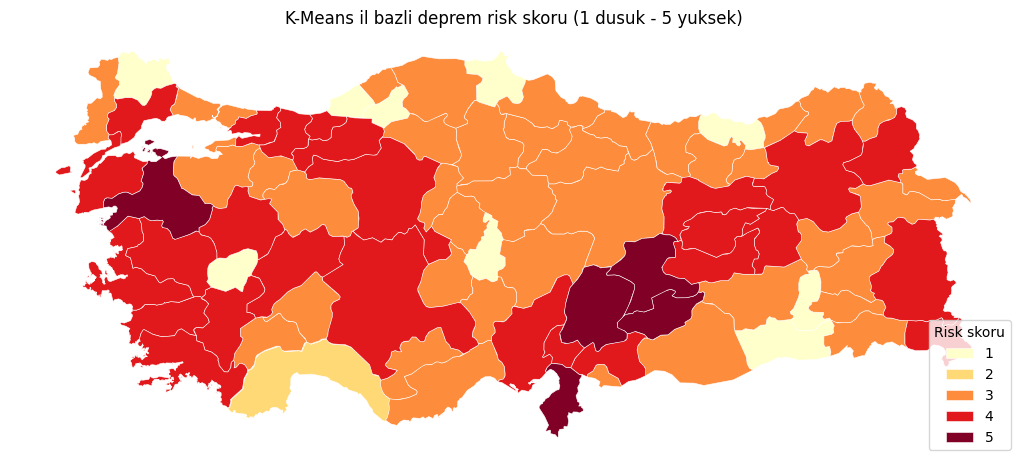

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

ESIK = 4.0       # sadece M>=4.0
MAX_KM = 30      # kiyidan en fazla 30 km uzaktaki deniz depremleri en yakin ile atanir
RAW = "https://raw.githubusercontent.com/nisanurguzel/deprem-sigorta-riskanalizi/main/01_Veri/"

# --- 1) Veriler ---
df = pd.read_csv(RAW + "deprem_temiz.csv", parse_dates=["time"])
d = df[df["mag"] >= ESIK].copy()

iller = gpd.read_file("https://raw.githubusercontent.com/cihadturhan/tr-geojson/master/geo/tr-cities-utf8.json")
iller = iller.set_crs(4326) if iller.crs is None else iller.to_crs(4326)
il_sutunu = [c for c in iller.columns if c != "geometry" and iller[c].dtype == "object"][0]
iller_m = iller[[il_sutunu, "geometry"]].to_crs(32636)   # metre cinsinden

noktalar = gpd.GeoDataFrame(d, geometry=gpd.points_from_xy(d["longitude"], d["latitude"]), crs=4326).to_crs(32636)

# --- 2) Once sinir icindekiler, sonra 30 km icindeki deniz depremleri ---
ic = gpd.sjoin(noktalar, iller_m, predicate="within", how="inner")
ic = ic[~ic.index.duplicated()]
disarida = noktalar.loc[~noktalar.index.isin(ic.index)]
yakin = gpd.sjoin_nearest(disarida, iller_m, how="inner", max_distance=MAX_KM * 1000)
yakin = yakin[~yakin.index.duplicated()]
bagli = pd.concat([ic, yakin]).rename(columns={il_sutunu: "il"})

print(f"M>={ESIK} deprem: {len(d)}")
print(f"  Sinir icinde: {len(ic)} | {MAX_KM} km icindeki deniz: {len(yakin)} | Atanamayan: {len(d) - len(bagli)}")

# --- 3) Il bazli ozellikler ---
tum_iller = sorted(iller[il_sutunu].unique())
ozet = bagli.groupby("il").agg(
    deprem_sayisi=("mag", "size"), maks_mag=("mag", "max"),
    m5_sayisi=("mag", lambda x: (x >= 5).sum()), ort_derinlik=("depth", "mean"))
artci = (bagli["time"] >= "2023-02-06") & (bagli["time"] < "2023-03-07")
ozet["deprem_sayisi_artcisiz"] = bagli[~artci].groupby("il").size()
son10 = bagli[(bagli["yil"] >= 2016) & (bagli["yil"] <= 2025)]
yillik = son10.groupby(["il", "yil"]).size().unstack(fill_value=0).reindex(columns=range(2016, 2026), fill_value=0)
ozet["son10_egilim"] = yillik.apply(lambda s: np.polyfit(range(10), s.values, 1)[0], axis=1)
ozet["son10_toplam"] = yillik.sum(axis=1)
ozet = ozet.reindex(tum_iller)
for c in ["deprem_sayisi", "maks_mag", "m5_sayisi", "deprem_sayisi_artcisiz", "son10_egilim", "son10_toplam"]:
    ozet[c] = ozet[c].fillna(0)
ozet["ort_derinlik"] = ozet["ort_derinlik"].fillna(ozet["ort_derinlik"].mean())
ozet.index.name = "il"

nufus = pd.read_csv(RAW + "il_ozellikleri_nufus.csv", index_col=0)["nufus"]
ozet["nufus"] = nufus.reindex(ozet.index)
t = ozet.round(2)

# --- 4) K-Means ---
X = pd.DataFrame(index=t.index)
X["log_deprem"] = np.log1p(t["deprem_sayisi_artcisiz"])
X["maks_mag"] = t["maks_mag"]
X["log_m5"] = np.log1p(t["m5_sayisi"])
X["ort_derinlik"] = t["ort_derinlik"]
X["son10_egilim"] = t["son10_egilim"]
Z = StandardScaler().fit_transform(X)
t["kume"] = KMeans(n_clusters=5, n_init=20, random_state=42).fit(Z).labels_

Zdf = pd.DataFrame(Z, index=X.index, columns=X.columns)
t["tehlike_puani"] = ((Zdf["log_deprem"] + Zdf["maks_mag"] + Zdf["log_m5"] - Zdf["ort_derinlik"]) / 4).round(2)
sira = t.groupby("kume")["tehlike_puani"].mean().rank().astype(int)
t["risk_skoru"] = t["kume"].map(sira)

KATSAYI = {1: 1.00, 2: 1.15, 3: 1.30, 4: 1.45, 5: 1.60}
t["prim_katsayisi"] = t["risk_skoru"].map(KATSAYI)

print("\nSkor basina il sayisi:")
print(t["risk_skoru"].value_counts().sort_index())
for s in range(5, 0, -1):
    liste = t[t["risk_skoru"] == s].sort_values("tehlike_puani", ascending=False).index.tolist()
    print(f"\nRisk {s} ({len(liste)} il): {', '.join(liste)}")

kontrol = [i for i in ["İstanbul", "Kocaeli", "Sakarya", "Düzce", "Antalya", "Ankara", "İzmir", "Muğla"] if i in t.index]
print("\nKontrol illeri:")
print(t.loc[kontrol, ["deprem_sayisi_artcisiz", "maks_mag", "m5_sayisi", "risk_skoru"]])

# --- 5) Harita ve kayit ---
harita = iller.merge(t[["risk_skoru"]], left_on=il_sutunu, right_index=True, how="left")
fig, ax = plt.subplots(figsize=(13, 6))
harita.plot(column="risk_skoru", cmap="YlOrRd", categorical=True, legend=True,
            edgecolor="white", linewidth=0.4, ax=ax,
            legend_kwds={"title": "Risk skoru", "loc": "lower right"})
ax.set_title("K-Means il bazli deprem risk skoru (1 dusuk - 5 yuksek)")
ax.set_axis_off()
plt.savefig("risk_haritasi_v2.png", dpi=150, bbox_inches="tight")
plt.show()

t.to_csv("il_prim_katsayilari_v2.csv", encoding="utf-8-sig")
from google.colab import files
files.download("il_prim_katsayilari_v2.csv")
files.download("risk_haritasi_v2.png")

In [10]:
import numpy as np
import pandas as pd

# Colab'a dosya yüklediysen veya Drive'dan okuyorsan yolu güncelle
# Örnek: df = pd.read_csv("deprem_temiz.csv")
df = pd.read_csv("deprem_temiz.csv")

print("Başlangıç satır sayısı:", len(df))
print("Sütunlar:", df.columns.tolist())

# Tarih sütununu düzenle (sütun adını kendi verine göre uyarla: 'time' veya 'tarih')
time_col = "time" if "time" in df.columns else df.columns[0]
df[time_col] = pd.to_datetime(df[time_col], errors="coerce")
df = df.dropna(subset=[time_col]).copy()

# Temel temizlik: koordinat, derinlik ve büyüklük kontrolü
if "depth" in df.columns:
  df["depth"] = pd.to_numeric(df["depth"], errors="coerce")
  df = df[df["depth"] >= 0]

if "mag" in df.columns:
  df["mag"] = pd.to_numeric(df["mag"], errors="coerce")
  df = df.dropna(subset=["mag"])

# 6 Şubat 2023 artçılarının ele alınması:
# Yaklaşım: 6 Şubat 2023 (01:17 UTC civarı) sonrası belirli bir penceredeki (ör. 30 gün)
# ve ana şoktan (Mw 7.8 / 7.6) küçük olayları 'aftershock_6feb' olarak işaretleyip
# analizde ayırma veya ayrı raporlama (kılavuzda nasıl ele aldığını açıkça yazmalısın!)
start_6feb = pd.Timestamp("2023-02-06 00:00:00", tz=df[time_col].dt.tz)
end_6feb_window = pd.Timestamp(
    "2023-03-08 23:59:59", tz=df[time_col].dt.tz
)

df["is_6feb_window"] = (df[time_col] >= start_6feb) & (
    df[time_col] <= end_6feb_window
)
print("6 Şubat sonrası 30 günlük penceredeki kayıt sayısı:", df["is_6feb_window"].sum())

Başlangıç satır sayısı: 19375
Sütunlar: ['id', 'time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'place', 'yil']
6 Şubat sonrası 30 günlük penceredeki kayıt sayısı: 482
